# EDA Sederhana · TT Dataset (EADRO)

**Mata kuliah:** Analisa dan Pemrosesan Data Multimodal · **Data:** *TT Dataset* (benchmark Train Ticket yang dipakai paper EADRO)

## Tujuan notebook ini

Sebelum membangun model, kita perlu **mengenal datanya dulu**. Notebook ini menjawab lima pertanyaan sederhana:

1. Apa saja isi dataset ini, dan seberapa besar?
2. Seperti apa **label**-nya (kapan dan di mana *fault* disuntikkan)?
3. Seperti apa tiga **modalitas**-nya (metrics, logs, traces): bentuk, isi, dan kualitasnya?
4. Apakah ketiga modalitas itu **bisa disejajarkan** pada sumbu waktu yang sama?
5. Apakah *fault* benar-benar meninggalkan jejak, dan **di modalitas mana**?

Untuk menjaga agar mudah diikuti, pembahasan detail memakai **satu run saja (R1)**; ringkasan seluruh run hanya dipakai di bagian inventaris dan label. Pemeriksaan yang lebih dalam (baseline tanpa fault, run yang bermasalah, dst.) ada di `EDA.ipynb`.

## Gambaran besar: apa itu TT Dataset?

**Train Ticket (TT)** adalah aplikasi pemesanan tiket kereta yang dibuat sebagai *microservice*: bukan satu program besar, tetapi **27 program kecil** (disebut *service*, semuanya berawalan `ts-`, misalnya `ts-travel-service`, `ts-order-service`) yang saling memanggil. Bayangkan sebuah restoran: ada pelayan, koki, kasir, dan gudang. Kalau satu orang lelet, seluruh restoran ikut lambat.

Para peneliti menjalankan aplikasi ini sambil **sengaja merusak** satu service pada waktu tertentu (*fault injection*), lalu merekam kondisi sistem. Ada tiga jenis kerusakan:

| Fault | Artinya | Analogi restoran |
|---|---|---|
| `cpu_load` | prosesor service dibebani berat | koki dipaksa mengerjakan tugas lain sampai kewalahan |
| `network_delay` | jaringan ke service diperlambat | jalur pelayan ke dapur macet |
| `network_loss` | sebagian paket jaringan ke service hilang | sebagian pesanan hilang di jalan |

Tugas model nanti (*root cause localization*): **dari data yang terekam, tebak service mana yang dirusak.**

### Tiga modalitas + label

| Modalitas | Bentuk data | Menjawab pertanyaan | Analogi |
|---|---|---|---|
| **Metrics** | deret waktu angka (CPU, memori, jaringan), 1 baris per detik per service | "Seberapa sibuk mesinnya?" | monitor detak jantung |
| **Logs** | teks, baris catatan yang ditulis service | "Apa yang sedang dikerjakan?" | buku harian |
| **Traces** | struktur pohon: satu permintaan pengguna melewati beberapa service; tiap langkah disebut *span* dan punya durasi | "Berapa lama tiap langkah?" | resi pelacakan paket |
| **Label** (`fault.json`) | daftar fault: service, jenis, waktu mulai, durasi | "Kunci jawaban" | kunci jawaban ujian |

Karena bentuknya sangat berbeda (angka, teks, pohon), inilah yang membuat dataset ini **multimodal**.

## 0. Persiapan

Sel berikut mengimpor *library* dan menentukan lokasi data. `RUNS` adalah daftar *run* (satu sesi percobaan) yang ada di folder `data/`. Setiap run diberi nama pendek `R1…R9` berdasarkan urutan waktu. `RUN` adalah run yang kita bedah detail: **R1**.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

# Lokasi data, relatif terhadap lokasi notebook (folder "EADRO - APDM")
BASE = Path("TT Dataset/TT Dataset")
DATA = BASE / "data"

# Satu nama folder = satu run, bentuknya TT.<waktu mulai>D<waktu selesai>
RUNS = sorted(p.name[3:] for p in DATA.glob("TT.20*") if p.is_dir())
RID = {run: f"R{i}" for i, run in enumerate(RUNS, 1)}
RUN = RUNS[0]                       # run yang dibedah detail (R1)
RUN_DIR = DATA / f"TT.{RUN}"

# Warna tetap per jenis fault, dipakai di semua grafik
FAULT_COLOR = {"cpu_load": "#2a78d6", "network_delay": "#eb6834", "network_loss": "#1baf7a"}
BLUE = "#2a78d6"


def pendek(nama):
    # "ts-travel-service" -> "travel" (hanya awalan/akhiran, bukan "ts-" di tengah kata)
    return nama.removeprefix("ts-").removesuffix("-service")


pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.color": "#e4e4e0", "grid.linewidth": 0.7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelsize": 9.5, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "figure.autolayout": True,
})

print("Jumlah run berfault:", len(RUNS))
print("Run yang dibedah   :", RID[RUN], "->", RUN)

Jumlah run berfault: 9
Run yang dibedah   : R1 -> 2022-04-17T212101D2022-04-17T230842


## 1. Inventaris: apa saja isinya?

Struktur folder (hasil ekstrak `TT Dataset.zip`):

```
TT Dataset/TT Dataset/
├── data/                         <- 9 run BERFAULT (dipakai di notebook ini)
│   ├── TT.<mulai>D<selesai>/     <- satu folder per run
│   │   ├── spans.json            <- TRACES
│   │   ├── logs.json             <- LOGS
│   │   └── metrics/ts-*.csv      <- METRICS (satu file per service)
│   └── TT.fault-<mulai>D<selesai>.json   <- LABEL untuk run itu
├── no fault/                     <- 3 run TANPA fault (masih berupa arsip, tidak dipakai di sini)
└── TT-all.txz                    <- arsip; isinya salinan data/
```

Tabel berikut merangkum setiap run di `data/`: berapa lama berjalan, berapa fault yang disuntikkan, dan ukuran tiap modalitas.

In [2]:
rows = []
for run in RUNS:
    fj = json.load(open(DATA / f"TT.fault-{run}.json"))
    d = DATA / f"TT.{run}"
    rows.append({
        "run": RID[run],
        "mulai (dari nama folder)": run[:15],
        "durasi (menit)": round((fj["end"] - fj["start"]) / 60, 1),
        "jumlah fault": len(fj["faults"]),
        "spans.json (MB)": round((d / "spans.json").stat().st_size / 1e6, 1),
        "logs.json (MB)": round((d / "logs.json").stat().st_size / 1e6, 1),
        "file metrics": len(list((d / "metrics").glob("*.csv"))),
    })
inventaris = pd.DataFrame(rows).set_index("run")
display(inventaris)

,mulai (dari nama folder),durasi (menit),jumlah fault,spans.json (MB),logs.json (MB),file metrics
run,,,,,,
R1,2022-04-17T2121,107.7,9,42.8,1.7,27
R2,2022-04-18T1025,107.7,9,76.9,2.1,27
R3,2022-04-18T1215,107.7,9,76.8,2.0,27
R4,2022-04-18T1507,107.7,9,43.4,1.1,27
R5,2022-04-18T1658,107.7,9,43.3,1.8,27
R6,2022-04-18T1847,107.7,9,43.5,1.9,27
R7,2022-04-18T2038,107.7,9,41.6,1.8,27
R8,2022-04-18T2228,107.7,9,41.6,1.8,27
R9,2022-04-19T0017,107.7,9,41.2,1.6,27


> **Temuan 1.** Ada **9 run berfault**, masing-masing sekitar **108 menit** dengan **9 fault** dan **27 file metrics** (satu per service). Modalitas terbesar adalah **traces** (40-77 MB per run), sedangkan logs hanya 1-2 MB. Ukuran `spans.json` terbagi dua kelompok (±42 MB dan ±77 MB), tetapi ukuran ini **tidak mencerminkan jumlah data sebenarnya**: di bagian 5-6 kita akan melihat bahwa file traces memuat banyak data ganda dan trace dari luar waktu run.

## 2. Label: kapan dan di mana fault disuntikkan?

File `TT.fault-<run>.json` adalah "kunci jawaban". Isinya: waktu mulai dan selesai run, serta daftar fault. Setiap fault punya `name` (nama container Docker, nama service ada di tengahnya), `fault` (jenis), `start` (epoch, yaitu detik sejak 1 Jan 1970), dan `duration` (detik).

Fungsi `read_faults` membaca file itu dan mengubahnya menjadi tabel. Kolom `t0` dan `t1` adalah **detik sejak awal run**, supaya mudah dibaca.

In [3]:
def read_faults(run):
    # Baca label satu run -> (isi mentah json, tabel fault).
    fj = json.load(open(DATA / f"TT.fault-{run}.json"))
    df = pd.DataFrame(fj["faults"])
    df["service"] = df["name"].str.split("_").str[1]      # dockercomposemanifests_<service>_1
    df["t0"] = df["start"] - fj["start"]                  # detik sejak awal run
    df["t1"] = df["t0"] + df["duration"]
    return fj, df[["service", "fault", "t0", "t1", "duration"]]

fj, faults = read_faults(RUN)
RUN_START, RUN_END = fj["start"], fj["end"]               # epoch pada jam fault.json

print("Isi mentah (dipotong):")
print(json.dumps(fj, indent=2)[:420], "...\n")
print(f"Tabel fault {RID[RUN]}:")
display(faults.round(0).astype({"t0": int, "t1": int, "duration": int}))

Isi mentah (dipotong):
{
  "start": 1650172861.377429,
  "faults": [
    {
      "name": "dockercomposemanifests_ts-food-service_1",
      "fault": "cpu_load",
      "start": 1650172864.064904,
      "duration": 600
    },
    {
      "name": "dockercomposemanifests_ts-food-service_1",
      "fault": "network_delay",
      "start": 1650173578.637172,
      "duration": 600
    },
    {
      "name": "dockercomposemanifests_ts-food-service_1 ...

Tabel fault R1:


,service,fault,t0,t1,duration
0,ts-food-service,cpu_load,3,603,600
1,ts-food-service,network_delay,717,1317,600
2,ts-food-service,network_loss,1442,2042,600
3,ts-travel-service,cpu_load,2157,2757,600
4,ts-travel-service,network_delay,2871,3471,600
5,ts-travel-service,network_loss,3595,4195,600
6,ts-contacts-service,cpu_load,4311,4911,600
7,ts-contacts-service,network_delay,5025,5625,600
8,ts-contacts-service,network_loss,5749,6349,600


Pola yang terlihat: R1 menyuntikkan **3 jenis fault ke tiap dari 3 service** (`food`, `travel`, `contacts`), **satu per satu**, masing-masing 600 detik, dengan jeda sekitar 2 menit di antaranya. Berikut ringkasan untuk **seluruh 9 run**, lalu garis waktu R1.

In [4]:
semua = pd.concat([read_faults(r)[1].assign(run=RID[r]) for r in RUNS], ignore_index=True)

print("Total kejadian fault   :", len(semua))
print("Service unik di-fault  :", semua.service.nunique())
print("Lama tiap fault (detik):", [int(x) for x in sorted(semua.duration.unique())])
print("\nJumlah per jenis fault:")
print(semua.fault.value_counts().to_string())
print("\nBerapa kali tiap pasangan (service, jenis fault) muncul:",
      [int(x) for x in sorted(semua.groupby(["service", "fault"]).size().unique())])

Total kejadian fault   : 81
Service unik di-fault  : 27
Lama tiap fault (detik): [600]

Jumlah per jenis fault:
fault
cpu_load         27
network_delay    27
network_loss     27

Berapa kali tiap pasangan (service, jenis fault) muncul: [1]


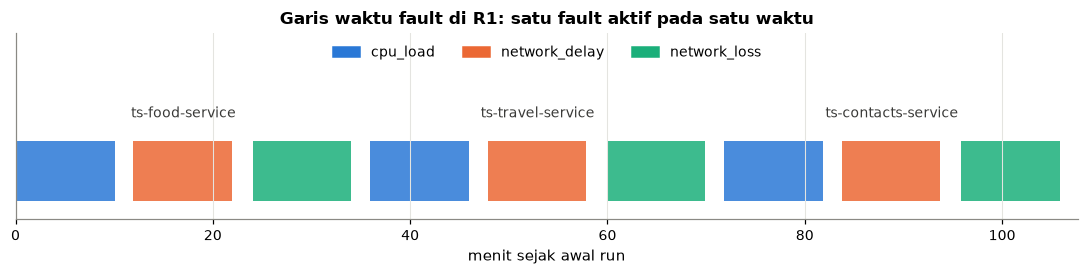

In [5]:
fig, ax = plt.subplots(figsize=(10, 2.6))
for _, f in faults.iterrows():
    ax.barh(0, (f.t1 - f.t0) / 60, left=f.t0 / 60, height=0.5, color=FAULT_COLOR[f.fault], alpha=0.85)
# nama service ditaruh di atas kelompok 3 fault yang sama
for svc, g in faults.groupby("service", sort=False):
    ax.text((g.t0.min() + g.t1.max()) / 120, 0.42, svc, ha="center", va="bottom", fontsize=9, color="#3a3a38")
ax.set_xlim(0, (RUN_END - RUN_START) / 60)
ax.set_ylim(-0.4, 1.15)
ax.set_yticks([])
ax.set_xlabel("menit sejak awal run")
ax.set_title(f"Garis waktu fault di {RID[RUN]}: satu fault aktif pada satu waktu")
ax.legend(handles=[Patch(color=c, label=k) for k, c in FAULT_COLOR.items()],
          loc="upper center", ncol=3, frameon=False, fontsize=9)
ax.grid(axis="y", visible=False)
plt.show()

> **Temuan 2.**
> - Seluruh dataset berisi **81 kejadian fault** (9 run x 9), semuanya **600 detik**: 27 `cpu_load`, 27 `network_delay`, 27 `network_loss`. Tiap service dirusak di **satu run saja**, dan tiap pasangan (service, jenis fault) hanya muncul **1 kali**.
> - **Dampak ke pemodelan:** tidak ada pengulangan, jadi data latih dan uji tidak boleh dipisah per baris secara acak (jendela fault yang sama akan muncul di kedua sisi). Pisahkan **per kejadian fault atau per run**.
> - Nyaris **tidak ada waktu "normal"** di dalam run: fault datang beruntun dengan jeda hanya sekitar 2 menit. Data normal sungguhan ada di folder `no fault/`.

## 3. Modalitas 1: Metrics (deret waktu angka)

Setiap service punya satu file CSV berisi pengukuran **per detik**. Kita buka milik `ts-travel-service` (service yang dirusak di tengah R1).

In [6]:
M = pd.read_csv(RUN_DIR / "metrics" / "ts-travel-service.csv")
print("Bentuk tabel:", M.shape, "(baris x kolom)\n")
display(M.head(4))
print("\nSelang antar baris (detik) dan banyaknya:")
print(M.timestamp.diff().value_counts().head(3).to_string())
print("\nNilai kosong per kolom:", int(M.isna().sum().sum()))
display(M.drop(columns="timestamp").describe().T[["mean", "std", "min", "50%", "max"]])

Bentuk tabel: (6461, 8) (baris x kolom)



,timestamp,cpu_usage_system,cpu_usage_total,cpu_usage_user,memory_usage,memory_working_set,rx_bytes,tx_bytes
0,1650172861,0.005,0.034998,0.03,0.003460,0.003443,4159.0,5896.5
1,1650172862,0.005,0.034998,0.03,0.003460,0.003443,4159.0,5896.5
2,1650172863,0.000,0.001210,0.00,0.003459,0.003442,0.0,0.0
3,1650172864,0.000,0.001210,0.00,0.003459,0.003442,0.0,0.0



Selang antar baris (detik) dan banyaknya:
timestamp
1.0    6460

Nilai kosong per kolom: 0


,mean,std,min,50%,max
cpu_usage_system,0.007858,0.024000,0.000000,0.000000,0.180000
cpu_usage_total,4.337080,14.043718,0.000264,0.001037,79.614307
cpu_usage_user,4.313879,13.972137,0.000000,0.000000,79.110000
memory_usage,0.003501,0.000044,0.003457,0.003483,0.004020
memory_working_set,0.003483,0.000042,0.003441,0.003466,0.003999
rx_bytes,172.804171,828.565897,0.000000,0.000000,8450.000000
tx_bytes,194.016561,1073.502959,0.000000,0.000000,11921.000000


**Cara membaca.**
- `timestamp` adalah waktu dalam epoch (detik). Satu baris = satu detik, sehingga run 108 menit menghasilkan sekitar 6.460 baris.
- Ada 3 kelompok kolom: **CPU** (`cpu_usage_system`, `cpu_usage_user`, `cpu_usage_total`), **memori** (`memory_usage`, `memory_working_set`), dan **jaringan** (`rx_bytes` diterima, `tx_bytes` dikirim).
- Tidak ada nilai kosong dan selang antar baris selalu 1 detik, jadi metrics adalah modalitas yang paling rapi.
- Satuan pasti tiap kolom tidak didokumentasikan, jadi kita hanya membandingkan **secara relatif** (naik atau turun dibanding kondisi sebelumnya).

Perhatikan `cpu_usage_total`: rata-ratanya jauh lebih besar dari median dan nilai maksimumnya hampir 80. Itu jejak fault `cpu_load`. Kita lihat langsung di grafik; area berwarna adalah jendela fault dan label di atasnya adalah service yang dirusak.

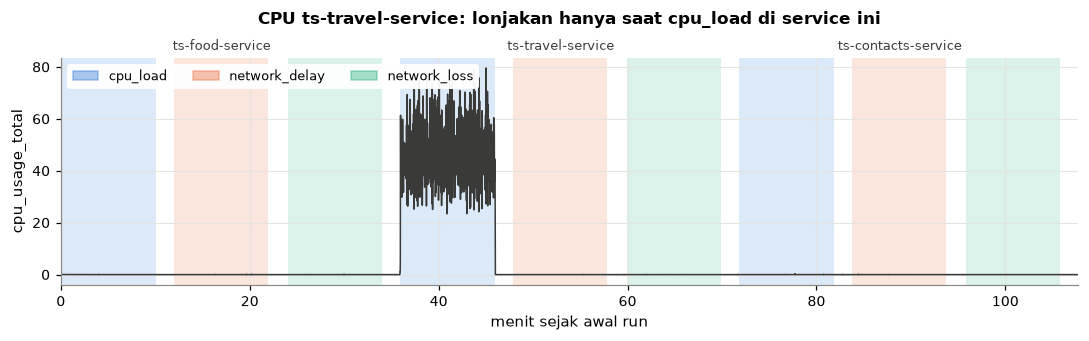

In [7]:
def shade_faults(ax, faults, with_names=False):
    # Warnai jendela fault (menit sejak awal run) sesuai jenis fault.
    for _, f in faults.iterrows():
        ax.axvspan(f.t0 / 60, f.t1 / 60, color=FAULT_COLOR[f.fault], alpha=0.16, lw=0)
    if with_names:
        for svc, g in faults.groupby("service", sort=False):
            ax.text((g.t0.min() + g.t1.max()) / 120, 1.02, svc, ha="center", va="bottom", fontsize=8.5,
                    color="#3a3a38", transform=ax.get_xaxis_transform())

M["menit"] = (M.timestamp - RUN_START) / 60
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(M.menit, M.cpu_usage_total, color="#3a3a38", lw=1)
shade_faults(ax, faults, with_names=True)
ax.set_xlim(0, (RUN_END - RUN_START) / 60)
ax.set_xlabel("menit sejak awal run")
ax.set_ylabel("cpu_usage_total")
ax.set_title("CPU ts-travel-service: lonjakan hanya saat cpu_load di service ini", pad=22)
ax.legend(handles=[Patch(color=c, alpha=0.4, label=k) for k, c in FAULT_COLOR.items()],
          loc="upper left", frameon=True, facecolor="white", edgecolor="none", framealpha=0.95, fontsize=8.5, ncol=3)
plt.show()

> **Temuan 3.** Metrics bersih dan lengkap. CPU `ts-travel-service` melonjak dari hampir 0 ke puluhan **hanya** pada jendela `cpu_load` milik `travel`. Pada jendela `network_delay` dan `network_loss` CPU-nya tidak bergerak. CPU-nya juga tetap datar ketika yang dirusak adalah service lain (`food` dan `contacts`), jadi lonjakan itu benar-benar milik service yang dirusak. Artinya **metrics hanya "melihat" fault `cpu_load`** (setidaknya lewat kolom CPU; bagian 7 mengujinya lebih lanjut).

## 4. Modalitas 2: Logs (teks)

`logs.json` adalah kamus: kunci = nama service, nilai = daftar baris log (teks mentah). Kita muat, lalu hitung berapa baris yang dihasilkan tiap service.

Jumlah service di logs.json: 27 | total baris log: 8995
Service dengan 0 baris log : 13 dari 27


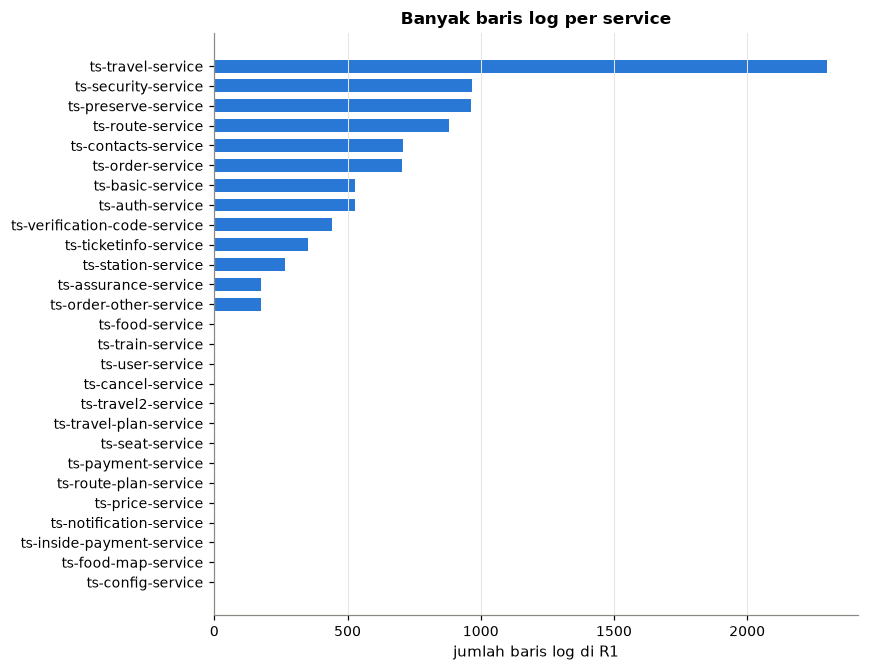

In [8]:
logs_raw = json.load(open(RUN_DIR / "logs.json"))
n_log = pd.Series({svc: len(v) for svc, v in logs_raw.items()}).sort_values()
print("Jumlah service di logs.json:", len(n_log), "| total baris log:", n_log.sum())
print("Service dengan 0 baris log :", int((n_log == 0).sum()), "dari", len(n_log))

fig, ax = plt.subplots(figsize=(8, 6.2))
ax.barh(n_log.index, n_log.values, color=BLUE, height=0.65)
ax.set_xlabel("jumlah baris log di R1")
ax.set_title("Banyak baris log per service")
ax.grid(axis="y", visible=False)
plt.show()

Sekarang lihat bentuk satu baris log. Sebagian besar baris mengikuti pola yang sama (format *Spring Boot*):

`waktu  LEVEL  nomor --- [thread]  nama.logger : pesan`

Kita pecah dengan *regular expression* menjadi kolom-kolom, supaya bisa dianalisis seperti tabel biasa.

In [9]:
L = pd.DataFrame([(svc, line) for svc, v in logs_raw.items() for line in v], columns=["service", "baris"])
pola = r"^(?P<waktu>\d{4}-\d\d-\d\d \d\d:\d\d:\d\d\.\d+)\s+(?P<level>\w+)\s+\d+ --- \[\s*(?P<thread>[^\]]*)\]\s+(?P<logger>\S+)\s*:\s(?P<pesan>.*)$"
L = L.join(L.baris.str.extract(pola)).drop(columns="baris")

print(f"Baris yang berhasil dipecah: {L.waktu.notna().mean():.1%} dari {len(L)}")
print("\nLevel log:", L.level.value_counts().to_dict())
span_rep = L.pesan.str.startswith("Span reported", na=False)
print(f"Baris 'Span reported': {span_rep.mean():.0%} dari semua log")
display(L[L.service == "ts-travel-service"].head(5)[["waktu", "level", "logger", "pesan"]])

Baris yang berhasil dipecah: 100.0% dari 8995

Level log: {'INFO': 8995}
Baris 'Span reported': 40% dari semua log


,waktu,level,logger,pesan
5990,2022-04-17 13:22:01.624,INFO,travel.controller.TravelController,[Travel Service] Query TripResponse
5991,2022-04-17 13:22:01.633,INFO,i.j.internal.reporters.LoggingReporter,Span reported: 35c5322013bd28c9:baa8a886485fc9a2:35c5322013bd28c9:1 - GET
5992,2022-04-17 13:22:01.634,INFO,travel.service.TravelServiceImpl,"Query for Station id is: Response(status=1, msg=Success, data=shanghai)"
5993,2022-04-17 13:22:01.640,INFO,i.j.internal.reporters.LoggingReporter,Span reported: 35c5322013bd28c9:f9d0498b53a2a4a2:35c5322013bd28c9:1 - GET
5994,2022-04-17 13:22:01.640,INFO,travel.service.TravelServiceImpl,"Query for Station id is: Response(status=1, msg=Success, data=suzhou)"


> **Temuan 4.**
> - Hampir semua baris bisa dipecah rapi, dan **semuanya berlevel `INFO`**: tidak ada `ERROR` atau `WARN`, jadi level log tidak bisa dipakai untuk mendeteksi fault.
> - Sekitar **separuh service tidak punya satu baris log pun** (atau hanya beberapa). Service-service ini tidak menerima lalu lintas dari skenario pengguna yang dijalankan, sehingga tidak ada yang dicatat.
> - Sekitar **40%** baris adalah `Span reported: <traceID>:<spanID>...`, yaitu catatan bahwa sebuah span telah dilaporkan. Baris ini adalah **jembatan antara log dan trace**: dengan `traceID`-nya, sebuah baris log bisa dihubungkan ke trace yang sama.
> - Isi pesan lainnya adalah teks bebas (misalnya `Query for Station id is: ...`). Untuk model nanti, teks ini perlu diubah dulu menjadi pola/templat atau angka.

## 5. Modalitas 3: Traces (pohon permintaan)

`spans.json` adalah daftar **trace**. Satu trace = satu permintaan pengguna (misalnya "cari tiket") yang berjalan melewati beberapa service. Di dalam trace ada banyak **span**, yaitu satu langkah/pemanggilan, masing-masing dengan:

- `spanID` dan `references` (span induknya), jadi hubungan antar span membentuk pohon,
- `startTime` (mikrodetik) dan `duration` (mikrodetik),
- `tags`: info tambahan (jenis span `client`/`server`, kode status HTTP, alamat URL),
- `processID`, yang lewat kamus `processes` di tingkat trace menunjukkan **service mana** pemilik span itu.

Struktur ini bersarang (trace > span > tag). Kita **ratakan** menjadi satu tabel, satu baris per span, dan ubah `duration` dari mikrodetik ke milidetik.

In [10]:
rows = []
for tr in json.load(open(RUN_DIR / "spans.json")):
    service_of = {pid: p["serviceName"] for pid, p in tr["processes"].items()}
    for s in tr["spans"]:
        tag = {t["key"]: t["value"] for t in s["tags"]}
        rows.append({
            "traceID": s["traceID"], "spanID": s["spanID"],
            "service": service_of[s["processID"]],
            "operasi": s["operationName"],
            "kind": tag.get("span.kind"),                 # client = pemanggil, server = penerima
            "status": tag.get("http.status_code"),
            "epoch": s["startTime"] / 1e6,                # detik
            "dur_ms": s["duration"] / 1000,               # milidetik
        })
SP_RAW = pd.DataFrame(rows)
print("Baris span hasil perataan:", len(SP_RAW))
display(SP_RAW.head(4))

Baris span hasil perataan: 18346


,traceID,spanID,service,operasi,kind,status,epoch,dur_ms
0,5d4e8e9f7697c45c,df62a7266345e4ec,ts-auth-service,GET,client,200,1.650201e+09,2.975
1,5d4e8e9f7697c45c,7a154a077e439226,ts-verification-code-service,verifyCode,server,200,1.650201e+09,1.499
2,5d4e8e9f7697c45c,5d4e8e9f7697c45c,ts-auth-service,getToken,server,200,1.650201e+09,126.233
3,d0fc26a00e4ff31a,e4f61a755533af87,ts-verification-code-service,verifyCode,server,200,1.650201e+09,1.927


### 5.1 Pemeriksaan kualitas: duplikasi

Satu span seharusnya muncul **sekali**. Identitasnya adalah pasangan `(traceID, spanID)`. Kita cek apakah ada yang muncul berkali-kali, dan apakah salinannya benar-benar sama persis.

In [11]:
kunci = ["traceID", "spanID"]
SP = SP_RAW.drop_duplicates(kunci).reset_index(drop=True)

print(f"Baris mentah        : {len(SP_RAW):>6}")
print(f"Span unik           : {len(SP):>6}  ({len(SP) / len(SP_RAW):.0%} dari baris mentah)")
print(f"Rata-rata salinan   : {len(SP_RAW) / len(SP):.1f}x per span")
print("Salinan identik 100%:", SP_RAW.duplicated().sum() == SP_RAW.duplicated(kunci).sum())
print("Jumlah trace unik   :", SP.traceID.nunique(), "| span per trace (median):", int(SP.groupby("traceID").size().median()))

Baris mentah        :  18346
Span unik           :   4588  (25% dari baris mentah)
Rata-rata salinan   : 4.0x per span
Salinan identik 100%: True
Jumlah trace unik   : 817 | span per trace (median): 3


> **Temuan 5.1.** `spans.json` **berisi sekitar 4 salinan identik untuk setiap span**: hanya sekitar seperempat baris yang unik. Penyebabnya tidak tercatat di dokumentasi (dugaan: data diambil beberapa kali dengan rentang waktu yang bertumpuk lalu digabung). Karena salinannya identik, aman dibuang. **Jika tidak dibuang, jumlah span dan rata-rata akan terhitung ±4 kali lipat.** Seluruh analisis berikutnya memakai `SP` (sudah tanpa duplikat).

### 5.2 Seperti apa durasi dan jenis span?

Jenis span (kind): {'server': 2667, 'client': 1921}
Kode status HTTP : {200: 4588}


,count,mean,std,min,25%,50%,75%,max
kind,,,,,,,,
client,1921.0,374.55,2755.86,1.28,2.80,4.30,7.88,65983.81
server,2667.0,434.43,4499.34,0.93,2.15,3.05,8.55,120264.68


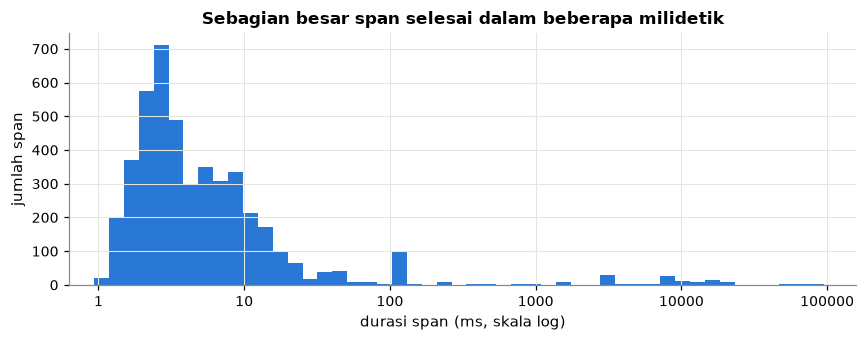

In [12]:
print("Jenis span (kind):", SP.kind.value_counts(dropna=False).to_dict())
print("Kode status HTTP :", SP.status.value_counts(dropna=False).to_dict())
display(SP.groupby("kind").dur_ms.describe().round(2))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(np.log10(SP.dur_ms), bins=50, color=BLUE)
ticks = [0, 1, 2, 3, 4, 5]
ax.set_xticks(ticks)
ax.set_xticklabels([f"{10.0 ** t:g}" for t in ticks])
ax.set_xlim(-0.2, 5.2)
ax.set_xlabel("durasi span (ms, skala log)")
ax.set_ylabel("jumlah span")
ax.set_title("Sebagian besar span selesai dalam beberapa milidetik")
plt.show()

> **Temuan 5.2.** Durasi span sangat miring: kebanyakan hanya beberapa milidetik, tetapi ada ekor panjang sampai puluhan ribu milidetik. Karena itu pakai **median** (bukan rata-rata) saat membandingkan latensi, dan pakai skala log saat menggambar. Di R1 **seluruh span berstatus HTTP 200** (sukses), jadi **kode status tidak bisa dipakai** untuk membedakan normal dan fault; sinyalnya ada di **durasi**.

## 6. Menyatukan ketiga modalitas pada satu sumbu waktu

Agar metrics, logs, dan traces bisa dibandingkan dengan label, semuanya harus memakai **jam yang sama**. Mari kita cek apakah memang begitu. Sel ini mencetak waktu awal tiap sumber.

In [13]:
def utc(epoch):
    return pd.Timestamp(epoch, unit="s", tz="UTC").strftime("%Y-%m-%d %H:%M:%S")

awal = {
    "label (fault.json): start run": utc(fj["start"]),
    "metrics: baris pertama": utc(M.timestamp.min()),
    "logs: baris pertama": L.waktu.min()[:19],        # teks waktu, dianggap UTC
}
for k, v in awal.items():
    print(f"{k:34s}{v}")
print(f"{'traces: span paling awal':34s}{utc(SP.epoch.min())}  <- ini dari hari sebelumnya, lihat 6.2")

label (fault.json): start run     2022-04-17 05:21:01
metrics: baris pertama            2022-04-17 05:21:01
logs: baris pertama               2022-04-17 13:22:01
traces: span paling awal          2022-04-16 13:25:02  <- ini dari hari sebelumnya, lihat 6.2


**Perhatikan:** label dan metrics mulai **05:21**, sedangkan logs mulai **13:22**. Selisihnya **8 jam** (ditambah 1 menit karena skrip beban baru mulai bekerja sekitar 1 menit setelah run dimulai). Jika kita abaikan ini, label akan menunjuk waktu yang salah.

### 6.1 Mencari offset secara empiris

Daripada langsung percaya, kita uji: geser waktu span sebanyak `h` jam (dari -12 sampai +12), lalu hitung berapa span yang jatuh **di dalam jendela run** menurut label. Geseran yang benar akan menghasilkan lonjakan yang jelas.

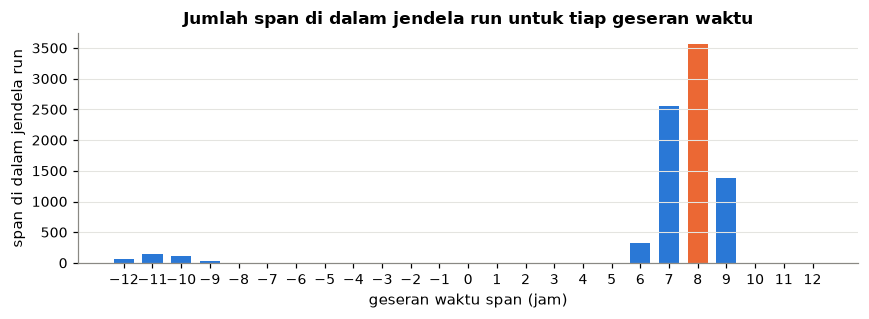

Offset yang dipakai: 28800 detik (8 jam)


In [14]:
geser = range(-12, 13)
jumlah = [int(((SP.epoch - h * 3600 >= RUN_START) & (SP.epoch - h * 3600 <= RUN_END)).sum()) for h in geser]

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(list(geser), jumlah, color=["#eb6834" if h == 8 else BLUE for h in geser], width=0.7)
ax.set_xticks(list(geser))
ax.set_xlabel("geseran waktu span (jam)")
ax.set_ylabel("span di dalam jendela run")
ax.set_title("Jumlah span di dalam jendela run untuk tiap geseran waktu")
ax.grid(axis="x", visible=False)
plt.show()
OFFSET_S = 8 * 3600
print("Offset yang dipakai:", OFFSET_S, "detik (8 jam)")

> **Temuan 6.1.** Puncak tertinggi ada pada geseran **+8 jam**. Geseran +7 dan +9 jam masih menangkap sebagian span karena jendela run berdurasi sekitar 1,8 jam, sehingga jendela yang digeser 1 jam masih tumpang tindih; di luar +6 sampai +9 jam, jumlahnya hampir nol. Jadi **spans dan logs memakai jam 8 jam lebih maju daripada label dan metrics** (dikuatkan oleh selisih waktu awal log pada bagian 6 di atas). Dugaan penyebab: konversi zona waktu (misalnya UTC+8) yang terjadi di satu sisi saja. Dugaan ini belum terbukti, tetapi offsetnya terbukti dari data. **Koreksi: kurangi waktu span dan log dengan 28.800 detik** sebelum dibandingkan dengan label.

### 6.2 Membersihkan traces: koreksi waktu dan buang trace di luar run

Setelah waktunya dikoreksi, kolom `det` berarti "detik sejak awal run". Span yang jatuh di luar `[0, durasi run]` adalah sisa trace dari sesi lain (sebelum atau sesudah run) dan harus dibuang. Pemeriksaan dilakukan per **trace** supaya satu trace tidak terpotong.

In [15]:
SP["det"] = SP.epoch - OFFSET_S - RUN_START               # detik sejak awal run (jam sudah sejajar)
t_awal = SP.groupby("traceID").det.transform("min")       # awal tiap trace
dalam = (t_awal >= 0) & (t_awal <= RUN_END - RUN_START)

print(f"Span unik            : {len(SP)}")
print(f"Di dalam waktu run   : {dalam.sum()}  ({dalam.mean():.0%})")
print(f"Di luar waktu run    : {(~dalam).sum()}  ({(~dalam).mean():.0%})  <- dibuang")
SPC = SP[dalam].copy()                                    # SPC = spans "clean"
print("Trace tersisa        :", SPC.traceID.nunique())

# logs ikut dikoreksi waktunya
L["det"] = (pd.to_datetime(L.waktu).dt.tz_localize("UTC") - pd.Timestamp("1970-01-01", tz="UTC")).dt.total_seconds() \
           - OFFSET_S - RUN_START

Span unik            : 4588
Di dalam waktu run   : 3564  (78%)
Di luar waktu run    : 1024  (22%)  <- dibuang
Trace tersisa        : 612


> **Temuan 6.2.** Sekitar **20% span unik berada di luar waktu run** (sisa trace dari sebelum run; yang tertua berasal dari hari sebelumnya). Di run lain angkanya bisa sampai hampir 50%. Setelah dibuang, tersisa trace milik R1 saja. **Urutan pembersihan traces: ratakan -> buang duplikat -> koreksi 8 jam -> buang trace di luar run.**

### 6.3 Service mana yang punya data di tiap modalitas?

Tidak semua service muncul di semua modalitas. Tabel ini menggabungkan hitungan dari ketiganya.

In [16]:
cakupan = pd.DataFrame({
    "baris_metrics": pd.Series({p.stem: len(pd.read_csv(p, usecols=["timestamp"])) for p in (RUN_DIR / "metrics").glob("*.csv")}),
    "baris_log": n_log,
    "span_unik": SPC.groupby("service").size(),
}).fillna(0).astype(int).sort_values("span_unik", ascending=False)

tak_ada = cakupan[(cakupan.span_unik == 0)]
print(f"Service di metrics     : {(cakupan.baris_metrics > 0).sum()} dari 27")
print(f"Service yang punya span: {(cakupan.span_unik > 0).sum()} dari 27")
print(f"Service TANPA span     : {len(tak_ada)} -> {', '.join(pendek(s) for s in tak_ada.index)}")
display(cakupan)

Service di metrics     : 27 dari 27
Service yang punya span: 13 dari 27
Service TANPA span     : 14 -> notification, inside-payment, cancel, config, food, food-map, seat, route-plan, payment, price, travel-plan, train, travel2, user


,baris_metrics,baris_log,span_unik
ts-travel-service,6461,2301,672
ts-route-service,6461,880,440
ts-basic-service,6461,528,352
ts-ticketinfo-service,6461,352,352
ts-order-service,6461,704,264
ts-station-service,6461,264,264
ts-security-service,6461,968,264
ts-preserve-service,6461,965,262
ts-verification-code-service,6461,440,176
ts-auth-service,6461,528,176


> **Temuan 6.3.** Metrics ada untuk **semua 27 service**, tetapi hanya sekitar **13 service yang punya span** (dan log yang berarti). 14 service lainnya tidak menerima lalu lintas dari skenario yang dijalankan, sehingga **bagi traces dan logs mereka "tidak terlihat"**. Konsekuensinya: kalau fault disuntikkan ke service seperti ini (misalnya `ts-food-service` di R1), hanya metrics yang berpotensi menangkapnya. Inilah alasan kuat untuk memakai banyak modalitas sekaligus.

## 7. Apakah fault meninggalkan jejak? Perbandingan antar modalitas

Inilah pertanyaan inti. Untuk setiap fault di R1 kita bandingkan kondisi **selama fault** dengan kondisi **100 detik sebelum fault** (masa jeda, saat belum ada fault lain yang aktif), pada **service yang dirusak**:

- dari **metrics**: median `cpu_usage_total`,
- dari **traces**: median durasi span (ms) dan banyaknya span.

Nilai `NaN` (kosong) muncul bila datanya tidak cukup: jendela pembanding terlalu pendek (fault pertama mulai di detik ke-3), atau service tidak punya span sama sekali, atau hanya punya kurang dari 3 span dalam 100 detik pembanding (angkanya terlalu kasar untuk dibandingkan).

In [17]:
PRE = 100                                                  # detik pembanding sebelum fault
metrics_cache = {}

def med(df, kolom, a, b, min_baris=1):
    x = df[(df.det >= a) & (df.det < b)][kolom]
    return x.median() if len(x) >= min_baris else np.nan

rows = []
for _, f in faults.iterrows():
    if f.service not in metrics_cache:
        m = pd.read_csv(RUN_DIR / "metrics" / f"{f.service}.csv")
        m["det"] = m.timestamp - RUN_START
        metrics_cache[f.service] = m
    m = metrics_cache[f.service]
    s = SPC[SPC.service == f.service]
    rows.append({
        "service": pendek(f.service),
        "fault": f.fault,
        "cpu sebelum": med(m, "cpu_usage_total", f.t0 - PRE, f.t0, 30),
        "cpu selama": med(m, "cpu_usage_total", f.t0, f.t1),
        "span selama": int(((s.det >= f.t0) & (s.det < f.t1)).sum()),
        "latensi sebelum (ms)": med(s, "dur_ms", f.t0 - PRE, f.t0, 3),
        "latensi selama (ms)": med(s, "dur_ms", f.t0, f.t1),
    })
dampak = pd.DataFrame(rows)
display(dampak.round(3))

,service,fault,cpu sebelum,cpu selama,span selama,latensi sebelum (ms),latensi selama (ms)
0,food,cpu_load,NaN,43.608,0,NaN,NaN
1,food,network_delay,0.001,0.001,0,NaN,NaN
2,food,network_loss,0.001,0.001,0,NaN,NaN
3,travel,cpu_load,0.001,43.335,80,3.561,2.770
4,travel,network_delay,0.001,0.001,40,4.175,7293.188
5,travel,network_loss,0.001,0.001,16,4.262,2248.818
6,contacts,cpu_load,0.001,43.655,20,2.406,2.328
7,contacts,network_delay,0.001,0.001,13,NaN,7290.553
8,contacts,network_loss,0.001,0.001,3,NaN,3137.101


**Cara membaca tabel.**

- `cpu_load` -> kolom **cpu** naik tajam (contoh: `travel` dari sekitar 0,001 menjadi puluhan), sementara **latensi tidak berubah**. Fault ini hanya terlihat di **metrics**, dan tetap terlihat di service tanpa trafik seperti `food`.
- `network_delay` dan `network_loss` -> kolom **cpu** tidak berubah, tetapi **latensi melonjak ratusan sampai ribuan kali lipat** (dari beberapa milidetik menjadi beberapa detik). Fault ini hanya terlihat di **traces**.
- `food`: tidak punya span sama sekali (kolom latensi kosong). Untuk service ini, `network_delay` dan `network_loss` **tidak meninggalkan jejak apa pun** di tabel ini.

Mari lihat ketiga modalitas dalam **satu gambar** untuk `ts-travel-service`. Logs ikut ditampilkan sebagai jumlah baris log per menit (jam sudah dikoreksi).

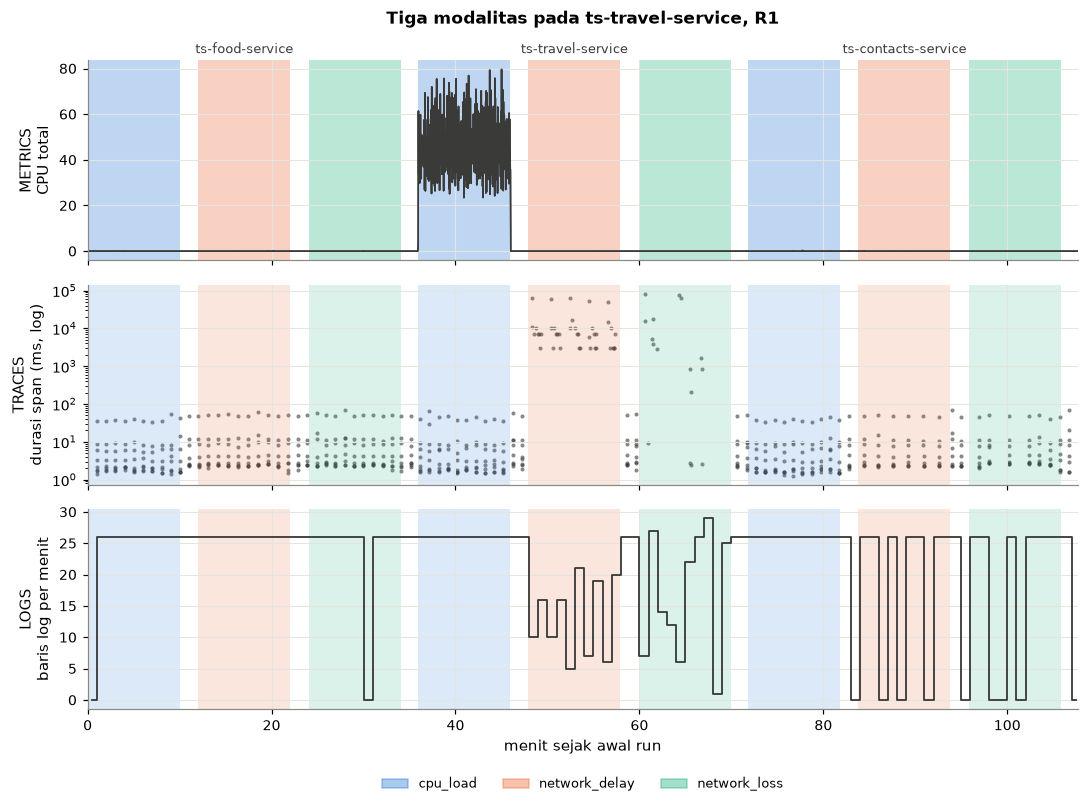

In [18]:
svc = "ts-travel-service"
m = metrics_cache[svc]
s = SPC[SPC.service == svc]
log_per_menit = (L[(L.service == svc) & (L.det >= 0)].det // 60).astype(int).value_counts()
log_per_menit = log_per_menit.reindex(range(int((RUN_END - RUN_START) // 60) + 1), fill_value=0).sort_index()

fig, axes = plt.subplots(3, 1, figsize=(10, 7.4), sharex=True)

axes[0].plot(m.det / 60, m.cpu_usage_total, color="#3a3a38", lw=1)
axes[0].plot(m.det / 60, m.cpu_usage_total, color="#3a3a38", lw=1)
axes[0].set_ylabel("METRICS\nCPU total")

axes[1].scatter(s.det / 60, s.dur_ms, s=7, color="#3a3a38", alpha=0.6, linewidths=0)
axes[1].set_yscale("log")
axes[1].set_ylabel("TRACES\ndurasi span (ms, log)")

axes[2].step(log_per_menit.index + 0.5, log_per_menit.values, where="mid", color="#3a3a38", lw=1.2)
axes[2].set_ylabel("LOGS\nbaris log per menit")
axes[2].set_xlabel("menit sejak awal run")

for ax in axes:
    shade_faults(ax, faults)
    ax.set_xlim(0, (RUN_END - RUN_START) / 60)
shade_faults(axes[0], faults, with_names=True)               # nama service di atas panel pertama
axes[0].set_title(f"Tiga modalitas pada ts-travel-service, {RID[RUN]}", pad=24)
axes[2].legend(handles=[Patch(color=c, alpha=0.4, label=k) for k, c in FAULT_COLOR.items()],
               loc="upper center", ncol=3, fontsize=8.5, frameon=True, facecolor="white",
               edgecolor="none", framealpha=0.95, bbox_to_anchor=(0.5, -0.28))
plt.show()

> **Temuan 7 (inti dari EDA ini).**
> - Tiap jenis fault punya "sidik jari" di **modalitas yang berbeda**: `cpu_load` terlihat di **metrics**, sedangkan `network_delay` dan `network_loss` terlihat di **traces**. Di **logs**, jumlah baris per menit menjadi naik-turun dan sering anjlok pada jendela network fault `travel`, tetapi **juga** pada jendela network fault `contacts`, padahal yang kita lihat adalah log milik `travel`. Dugaan: kedua service dipanggil dalam alur permintaan yang sama, sehingga saat salah satunya macet, seluruh alur melambat dan catatan log berkurang. Jadi logs menunjukkan "ada masalah di suatu tempat" tetapi **kurang tepat menunjuk service mana**, lebih lemah dibanding dua modalitas lain. **Tidak ada satu modalitas pun yang cukup untuk ketiga jenis fault.** Inilah dasar kuat untuk pendekatan multimodal dan alasan kita perlu memikirkan cara menggabungkan (*fusion*) modalitas.
> - Sebaliknya, untuk service yang tak punya trafik (`food`), traces dan logs buta; hanya metrics yang tersisa.
> - Tabel dan grafik di atas hanya untuk R1. Sinyal `network_*` di metrics (kolom `rx/tx`) tidak diuji di sini; di `EDA.ipynb` bagian 9 terlihat bahwa efeknya lemah dan tidak konsisten.

## 8. Kesimpulan dan implikasi untuk pemrosesan data

| # | Temuan | Dampak | Tindakan sebelum modeling |
|---|---|---|---|
| 1 | 9 run berfault x 9 fault = 81 kejadian; tiap (service, jenis) hanya 1 contoh | tidak ada pengulangan; risiko kebocoran data jika split per baris | pisahkan latih/uji **per kejadian fault atau per run** |
| 2 | Hampir tidak ada waktu normal di dalam run | sulit mengambil baseline "normal" | pakai run di `no fault/` sebagai baseline |
| 3 | Metrics bersih: 27 service, 1 baris/detik, tanpa nilai kosong | siap dipakai | normalisasi per service (satuan tak jelas) |
| 4 | Logs: semua `INFO`, teks bebas, separuh service kosong | level log tidak informatif | ubah pesan jadi templat/hitungan; pakai `Span reported` untuk menghubungkan ke trace |
| 5 | Traces: ±4x duplikat; ±20% di luar waktu run (di run lain sampai ±50%) | hitungan dan rata-rata menyesatkan jika tak dibersihkan | **dedup** `(traceID, spanID)` lalu **filter** ke jendela run |
| 6 | Jam spans/logs **+8 jam** terhadap label/metrics | label meleset jika tidak dikoreksi | kurangi 28.800 detik pada spans/logs |
| 7 | Hanya ±13 dari 27 service punya span/log | traces dan logs buta untuk 14 service | ketiga modalitas harus dibuat tahan terhadap data kosong |
| 8 | `cpu_load` terlihat di metrics; `network_*` di traces | modalitas saling melengkapi | rancang *fusion* yang bisa memanfaatkan keduanya |
| 9 | Latensi sangat miring (ekor panjang); kode status hampir selalu 200 | rata-rata dan status tidak informatif | pakai median/persentil dan skala log; fitur dari durasi |

### Yang belum dicakup (sengaja, supaya notebook ini ringkas)

- Baseline `no fault/` (masih berupa arsip yang perlu diekstrak).
- Delapan run lain: semua analisis detail memakai R1. Di `EDA.ipynb` ada pengecekan lintas-run; salah satu temuannya, run **R4** berhenti menghasilkan trace di tengah jalan.
- Satuan pasti kolom metrics, dan penyebab pasti duplikasi serta offset 8 jam (keduanya baru berupa dugaan).

### Langkah berikutnya

1. Putuskan ukuran **jendela waktu** (misalnya 30-60 detik) dan beri label per jendela dari tabel fault.
2. Bangun fitur per (service, jendela): statistik metrics, hitungan/templat log, statistik latensi.
3. Tentukan skema pembagian latih/uji **sebelum** membuat fitur.
4. Mulai membandingkan mekanisme fusion di atas fitur tersebut.